# 02 — Train Unet2D on fix-window data

Pipeline step 2: load fix-window `.npy` files, train `Unet2D` with day/hour conditioning, and save artifacts under `Models/`.

**Current training set:** `data/sample_16_19_fixwin_dt96_*` (2016–2019, 128×384, **DT=96 h** = 4-day frames). Set `DT = 96` in the load cell; `# DT = 24` is kept commented for daily exports. Other paths (`10_19`, `20_21`, daily) are commented in the load cell.

**Resumable / disconnect-safe training:** use the **launch cell** at the bottom (`DETACHED = True`). Progress is saved every epoch; re-run to resume.

**adv-NO variant (L1 + perceptual + adversarial):** see [04_train_adv_no_fix_window.ipynb](04_train_adv_no_fix_window.ipynb) and eval in [05_evaluate_adv_no_rollout.ipynb](05_evaluate_adv_no_rollout.ipynb).

**Outputs**
- `Models/best_model_FixWindow1.pth`
- `Models/norm_stats.pt`
- `Models/fix_window/resume_{RUN_NAME}.pt` — full resume checkpoint
- `Models/fix_window/history/training_history_{RUN_NAME}.pt` — loss curves

In [7]:
import numpy as np
import matplotlib.pyplot as plt
# import segmentation_models_pytorch as smp

from gUnet import Unet2D

In [8]:
# --- training data prefix (switch here) ---
DT = 96  # hours between frames (4-day steps)
# DT = 24  # daily frames
DT_STEP_DAYS = DT // 24

# Train (2016–2019, DT=96):
DATA_PREFIX = "data/sample_16_19_fixwin_dt96"
# DATA_PREFIX = "data/sample_16_19_fixwin"  # use with DT = 24

# Train (2010–2019, DT=96):
# DATA_PREFIX = "data/sample_10_19_fixwin_dt96"
# DATA_PREFIX = "data/sample_10_19_fixwin"  # use with DT = 24

simsNP = np.load(f"{DATA_PREFIX}_sims.npy", mmap_mode="r")
maskNP = np.load(f"{DATA_PREFIX}_mask.npy")
dayNP = np.load(f"{DATA_PREFIX}_day.npy")
hourNP = np.load(f"{DATA_PREFIX}_hour.npy")

CROP_HEIGHT, CROP_WIDTH = simsNP.shape[-2], simsNP.shape[-1]
print(f"Dataset: {DATA_PREFIX}")
print(f"Crop size: {CROP_HEIGHT} x {CROP_WIDTH}")
print(dayNP.shape)

Dataset: data/sample_16_19_fixwin_dt96
Crop size: 128 x 128
(1461,)


In [9]:
keep = np.all(maskNP == 0, axis=(1, 2))
maskNP = maskNP[keep]
simsNP = simsNP[keep]
dayNP = dayNP[keep]
hourNP = hourNP[keep]


In [10]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import numpy as np
import os
from datetime import datetime

# ----------------------------
# Dataset
# ----------------------------
class SimulationDataset(Dataset):
    """
    Expects data of shape [T, 3, H, W] — a time series of simulation snapshots.
    Returns (input: [9, H, W], target: [3, H, W]) pairs.
    """
    def __init__(self, data: torch.Tensor, mask: torch.Tensor, day:torch.Tensor, hour:torch.Tensor, mean=None, std=None, iD=3):
        self.iD = iD # input dim
        # data: [N, 7, 3, H, W]
        self.x = torch.cat([
            data[:, 0, :iD, :, :],   # [N, 3, H, W]
            data[:, 1, :iD, :, :],   # [N, 3, H, W]
            data[:, 2, :iD, :, :],   # [N, 3, H, W]
            data[:, 3, :iD, :, :],   # [N, 3, H, W]
        ], dim=1).float()                  # [N, 9, H, W]

        #self.y = (data[:, 4, :, :, :] - data[:, 3, :, :, :]).float()   # [N, 3, H, W]
        self.y = torch.cat([
            (data[:, 4, :iD, :, :] - data[:, 3, :iD, :, :]),   # [N, 3, H, W]
            (data[:, 5, :iD, :, :] - data[:, 4, :iD, :, :]),   # [N, 3, H, W]
            (data[:, 6, :iD, :, :] - data[:, 5, :iD, :, :]),   # [N, 3, H, W]
        ], dim=1).float() 

        self.mask = mask  # [N, H, W]

        # Compute stats from this data if not provided (i.e. training set)
        if mean is None:
            # mean/std over N, H, W — keep channel dim → shape [1, 9, 1, 1]
            self.mean = (
                data[:, 0,:iD].float().mean(dim=(0, 2, 3), keepdim=True) +
                data[:, 1,:iD].float().mean(dim=(0, 2, 3), keepdim=True) +
                data[:, 2,:iD].float().mean(dim=(0, 2, 3), keepdim=True) + 
                data[:, 3,:iD].float().mean(dim=(0, 2, 3), keepdim=True)
            ) / 4.0   
            # For std, pool all timesteps together for a more stable estimate
            self.std = torch.cat([
                data[:, 0,:iD].float(),
                data[:, 1,:iD].float(),
                data[:, 2,:iD].float(),
                data[:, 3,:iD].float(),                
            ], dim=0).std(dim=(0, 2, 3), keepdim=True)  # [1, 4, 1, 1]            

        else:
            self.mean = mean
            self.std  = std


        mean_x = self.mean.repeat(1, 4, 1, 1)  # [1, 9, 1, 1]
        std_x  = self.std.repeat(1, 4, 1, 1)   # [1, 9, 1, 1]

        std_y  = self.std.repeat(1, 3, 1, 1)   # [1, 9, 1, 1]
        # Normalize x
        self.x = (self.x - mean_x) / (std_x + 1e-8)        

        # Normalize y using only the first 3 channels stats (single timestep)
        self.y = self.y  / (std_y + 1e-8)

        #print(self.mean,self.std,"Delta ",self.y.min()-self.y.max(),self.x.min()-self.x.max())


        self.day = day.float()/365
        self.hour = hour.float()/365

    def __len__(self):
        return len(self.x)

    def __getitem__(self, idx):
        return self.x[idx], self.y[idx], self.mask[idx],self.day[idx],self.hour[idx]  # [9, H, W], [3, H, W], [H, W]


####################################################################
import torch
import torch.nn.functional as F


def spectral_loss(pred, target, eps=1e-8):
    """
    pred,target:
        [B,C,H,W]

    Computes spectral amplitude loss.
    """

    # FFT
    pred_fft = torch.fft.rfft2(pred)
    targ_fft = torch.fft.rfft2(target)

    # Amplitude spectra
    pred_amp = torch.abs(pred_fft)
    targ_amp = torch.abs(targ_fft)

    # Linear spectrum loss
    loss_amp = F.l1_loss(pred_amp, targ_amp)

    # Log spectrum loss
    loss_log = F.l1_loss(
        torch.log(pred_amp + eps),
        torch.log(targ_amp + eps)
    )

    return loss_amp + loss_log
####################################################################
def masked_relative_l2_loss(pred, target, mask, eps=1e-8):
    """
    Relative/scaled L2 loss.

    Computes:

        ||pred - target||_2 / ||target||_2

    only on valid pixels where mask == 0.

    pred:   [B, C, H, W]
    target: [B, C, H, W]
    mask:   [B, H, W]
    """

    # valid pixels
    valid = (mask == 0).unsqueeze(1).expand_as(pred)

    # apply mask
    pred_valid = pred * valid
    target_valid = target * valid

    # flatten per sample
    pred_valid = pred_valid.reshape(pred.shape[0], -1)
    target_valid = target_valid.reshape(target.shape[0], -1)

    # numerator: ||pred-target||_2
    num = torch.norm(pred_valid - target_valid, p=2, dim=1)

    # denominator: ||target||_2
    den = torch.norm(target_valid, p=2, dim=1) + eps

    # relative error per sample
    loss = num / den

    return loss.mean()
####################################################################
def masked_loss(pred, target, mask):
    """Only compute loss on pixels where mask == 0."""
    # mask: [B, H, W] → expand to [B, 3, H, W]
    valid = (mask == 0).unsqueeze(1).expand_as(pred)
    # return nn.functional.mse_loss(pred[valid], target[valid])
    return nn.functional.l1_loss(pred[valid], target[valid])
####################################################################
def create_spatial_weight(h=128, w=128, sigma=32):

    y = torch.arange(h).float()
    x = torch.arange(w).float()

    yy, xx = torch.meshgrid(y, x, indexing='ij')

    cy = (h - 1) / 2
    cx = (w - 1) / 2

    dist2 = (yy - cy) ** 2 + (xx - cx) ** 2

    weight = torch.exp(-dist2 / (2 * sigma ** 2))

    # normalize so mean weight ≈ 1
    weight = weight / weight.mean()

    return weight
####################################################################
def weighted_charbonnier_loss(
    pred,
    target,
    mask,
    spatial_weight,
    eps=1e-3,
):

    valid = (mask == 0).unsqueeze(1)

    # [1,1,H,W]
    spatial_weight = spatial_weight.to(pred.device)
    spatial_weight = spatial_weight.unsqueeze(0).unsqueeze(0)

    diff = pred - target

    loss = torch.sqrt(diff * diff + eps * eps)

    # apply:
    # - validity mask
    # - spatial weighting
    weighted_loss = loss * valid * spatial_weight

    return weighted_loss.sum() / (valid * spatial_weight).sum()
####################################################################
def gradient_loss(pred, target):

    dx_p = pred[:, :, :, 1:] - pred[:, :, :, :-1]
    dy_p = pred[:, :, 1:, :] - pred[:, :, :-1, :]

    dx_t = target[:, :, :, 1:] - target[:, :, :, :-1]
    dy_t = target[:, :, 1:, :] - target[:, :, :-1, :]

    return (
        nn.functional.l1_loss(dx_p, dx_t) +
        nn.functional.l1_loss(dy_p, dy_t)
    )
####################################################################
def myLoss(    pred,
    target,
    mask,
    spatial_weight,
    eps=1e-3,):

    return masked_loss(pred, target, mask) #+ 0.1 * gradient_loss(pred, target) + 0.05 * spectral_loss(pred, target)
    #return gradient_loss(pred, target) + 0.02 * spectral_loss(pred, target)
    #return weighted_charbonnier_loss(pred, target, mask, spatial_weight, eps)
####################################################################
####################################################################
####################################################################
# ----------------------------
# Training loop
# ----------------------------
def train(
    model: nn.Module,
    data: torch.Tensor,          # [T, 3, H, W]
    mask: torch.Tensor,          # [T, H, W]
    day: torch.Tensor,
    hour: torch.Tensor,
    epochs: int = 100,
    batch_size: int = 8,
    lr: float = 1e-4,
    val_split: float = 0.2,
    device: str = "cuda:7" if torch.cuda.is_available() else "cpu",
    iD: int = 3,
    checkpoint_dir: str = "Models/fix_window",
    run_name: str = "fix_window",
):
    print(f"Using device: {device}")
    model = model.to(device)

    # if torch.cuda.device_count() > 1:
    #     print(f"Using {torch.cuda.device_count()} GPUs")
    #     model = nn.DataParallel(model)

    # Split into train/val
    # Split raw data first
    N = len(data)
    n_test  = int(N * 0.2)
    n_train = N - n_test

    train_data = data[:n_train]
    train_mask = mask[:n_train]
    train_day = day[:n_train]
    train_hour = hour[:n_train]

    val_data   = data[n_train:]
    val_mask   = mask[n_train:]
    val_day   = day[n_train:]
    val_hour   = hour[n_train:]


    train_size = len(train_data)
    val_size   = len(val_data)

    # Train set computes its own stats
    train_set = SimulationDataset(train_data,train_mask,train_day,train_hour,iD=iD)

    # Val/test reuse train stats — critical to avoid data leakage
    val_set  = SimulationDataset(val_data,val_mask,val_day,val_hour, mean=train_set.mean, std=train_set.std,iD=iD)

    history_dir = os.path.join(checkpoint_dir, "history")
    os.makedirs(history_dir, exist_ok=True)

    norm_stats = {"mean": train_set.mean, "std": train_set.std}
    norm_stats_path = os.path.join(checkpoint_dir, "norm_stats.pt")
    torch.save(norm_stats, norm_stats_path)
    torch.save(norm_stats, "Models/norm_stats.pt")

    run_info = {
        "run_name": run_name,
        "started_at": datetime.now().isoformat(timespec="seconds"),
        "epochs_planned": epochs,
        "batch_size": batch_size,
        "lr": lr,
        "iD": iD,
        "train_size": train_size,
        "val_size": val_size,
        "device": str(device),
        "checkpoint_dir": checkpoint_dir,
    }
    torch.save(run_info, os.path.join(checkpoint_dir, "run_info.pt"))

    history_path = os.path.join(history_dir, f"training_history_{run_name}.pt")
    hist = {
        "epoch": [],
        "train": [],
        "val": [],
        "val1": [],
        "val2": [],
        "val3": [],
        "lr": [],
        "best_val_loss": float("inf"),
        "best_epoch": 0,
    }

    print(f"Checkpoints: {checkpoint_dir}")
    print(f"History:     {history_path}")

    # dataset = SimulationDataset(data)
    # val_size = int(len(dataset) * val_split)
    # train_size = len(dataset) - val_size
    # train_set, val_set = torch.utils.data.random_split(dataset, [train_size, val_size])

    train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
    val_loader   = DataLoader(val_set,   batch_size=batch_size, shuffle=False)

    h, w = data.shape[-2], data.shape[-1]
    scale = max(h, w) / 128.0
    spatial_weight = create_spatial_weight(h=h, w=w, sigma=96 * scale)
    spatial_weight1 = create_spatial_weight(h=h, w=w, sigma=64 * scale)
    spatial_weight2 = create_spatial_weight(h=h, w=w, sigma=32 * scale)

    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    #optimizer = torch.optim.AdamW(model.parameters(),lr=lr,weight_decay=1e-4)
    
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=5, factor=0.5)
    criterion = nn.MSELoss()

    best_val_loss = float("inf")
    best_epoch = 0
    
    #model.load_state_dict(torch.load("best_modelZXXX.pth"))

    for epoch in range(1, epochs + 1):
        # --- Train ---
        model.train()
        train_loss = 0.0
        for x, y,m,d,h in train_loader:
            x, y,m,d,h = x.to(device), y.to(device), m.to(device), d.to(device), h.to(device)           

            delta = torch.full_like(d, 4.0)  # [B] filled with 4.0, same device/dtype as d
            t = torch.stack([d, h,delta], dim=-1)  # [B, 2]
            t = t.unsqueeze(1).expand(-1, 3, -1).reshape(x.size(0), -1)  # [B, 6]           
           
            optimizer.zero_grad()
            #pred = model(x[:, -3*iD:],t)
            pred = model(x[:, -3*iD:],d+h/365.0)
            
            #pred = x[:, -6:-3] + 2.0 * pred
            #pred = 1.5 * pred - 0.5*(x[:, -3:]-x[:, -6:-3]) #<< diff
            
            #loss = criterion(pred, y)
            #loss = masked_loss(pred, y, m) 
            loss = myLoss(pred,y[:,:iD],m,spatial_weight)
            
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * x.size(0)
        train_loss /= train_size

        # --- Validate ---
        model.eval()
        val_loss,val_loss1, val_loss2, val_loss3 = 0.0, 0.0, 0.0,0.0

        with torch.no_grad():
            for x, y,m,d,h in val_loader:
                x, y,m,d,h = x.to(device), y.to(device), m.to(device), d.to(device), h.to(device)               
                
                delta = torch.full_like(d, 4.0)  # [B] filled with 4.0, same device/dtype as d
                t = torch.stack([d, h,delta], dim=-1)  # [B, 2]
                t = t.unsqueeze(1).expand(-1, 3, -1).reshape(x.size(0), -1)  # [B, 6]

                ## next 4 days
                #pred1 = model(x[:,-3*iD:],t)
                pred1 = model(x[:,-3*iD:],d+h/365.0)
                #pred1 = 1.5 * pred1 - 0.5*(x[:, -3:]-x[:, -6:-3]) # diff
                val_loss1 += myLoss(pred1,y[:,:iD],m,spatial_weight).item() * x.size(0)   

                # ## next 8 days  
                # t = torch.stack([d + 4.0/365.0, h, delta], dim=-1)  # [B, 3]
                # t = t.unsqueeze(1).expand(-1, 3, -1).reshape(x.size(0), -1)  # [B, 6]

                # x2 = torch.cat([x[:, 3:6],x[:, 6:9], pred1+x[:, -3:]], dim=1)
                # # x2 = torch.cat([x[:, 3:6],x[:, 6:9], 2.0*pred1+x[:, -6:-3]], dim=1)
                # pred2 = model(x2,t)
                # val_loss2 += myLoss(pred2,y[:,3:6],m,spatial_weight1).item() * x.size(0)  
                # ## next 12 days
                # t = torch.stack([d + 4.0/365.0, h, delta], dim=-1)  # [B, 3]
                # t = t.unsqueeze(1).expand(-1, 3, -1).reshape(x.size(0), -1)  # [B, 6]
                
                # x3 = torch.cat([x[:, 6:9],x2[:,-3:],pred2+x2[:, -3:]], dim=1)
                # # x3 = torch.cat([x[:, 6:9],x2[:,-3:],2.0*pred2+x2[:, -6:-3]], dim=1)
                # pred3 = model(x3,t)
                # val_loss3 += myLoss(pred3,y[:,6:],m,spatial_weight2).item() * x.size(0)  

        val_loss1 /= val_size
        val_loss2 /= val_size
        val_loss3 /= val_size

        scheduler.step(val_loss1)  # Use the first validation loss for scheduling

        val_loss = val_loss1 + 0.5*val_loss2 + 0.25*val_loss3
        current_lr = optimizer.param_groups[0]["lr"]

        hist["epoch"].append(epoch)
        hist["train"].append(train_loss)
        hist["val"].append(val_loss)
        hist["val1"].append(val_loss1)
        hist["val2"].append(val_loss2)
        hist["val3"].append(val_loss3)
        hist["lr"].append(current_lr)
        hist["best_val_loss"] = best_val_loss
        hist["best_epoch"] = best_epoch
        torch.save(hist, history_path)

        # --- Checkpoint ---
        if val_loss < best_val_loss:
            print(f"epoch {epoch} | val loss {val_loss:.6f} | > (improvement of {best_val_loss - val_loss:.6f})")
            best_val_loss = val_loss
            best_epoch = epoch
            hist["best_val_loss"] = best_val_loss
            hist["best_epoch"] = best_epoch
            best_model_path = os.path.join(checkpoint_dir, f"best_model_{run_name}.pth")
            torch.save(model.state_dict(), best_model_path)
            torch.save(model.state_dict(), "Models/best_model_FixWindow1.pth")
            torch.save(hist, history_path)

        torch.save(model.state_dict(), os.path.join(checkpoint_dir, f"last_model_{run_name}.pth"))

        if epoch % 1 == 0 or epoch == 1:
            print(f"Epoch {epoch:04d} | Train Loss: {train_loss:.6f} | Val Loss:{val_loss:.6f} > {val_loss1:.6f}, {val_loss2:.6f}, {val_loss3:.6f} | LR: {current_lr:.2e}")

    run_info["finished_at"] = datetime.now().isoformat(timespec="seconds")
    run_info["epochs_completed"] = len(hist["epoch"])
    run_info["best_val_loss"] = best_val_loss
    run_info["best_epoch"] = best_epoch
    torch.save(run_info, os.path.join(checkpoint_dir, "run_info.pt"))
    torch.save(hist, history_path)

    print(f"\nTraining complete. Best val loss: {best_val_loss:.6f} (epoch {best_epoch})")
    print(f"Saved history to {history_path}")
    return model


# ----------------------------
# Usage — see launch cell below (resumable + detached)
# ----------------------------
# Inline training (blocks kernel; not disconnect-safe):
# from src.train.fix_window_train import TrainConfig, run_training
# run_training(TrainConfig(data_prefix=DATA_PREFIX, run_name="fix_window_10_19"), resume=True)

## Launch training (resumable, disconnect-safe)

Runs `src/train/fix_window_train.py` in the background by default. Re-run this cell (or `./scripts/run_train_detached.sh fix_window_16_19_dt96`) to **resume** after SSH disconnect or server reboot.

- Progress: `Models/fix_window/train_state_{RUN_NAME}.json`
- Resume checkpoint: `Models/fix_window/resume_{RUN_NAME}.pt`
- Log: `logs/train_{RUN_NAME}.log`

In [11]:
import json
import subprocess
import sys
from dataclasses import asdict
from pathlib import Path

from src.train.fix_window_train import TrainConfig, run_training

RUN_NAME = "fix_window_16_19_dt96"
# RUN_NAME = "fix_window_10_19_dt96"  # 2010–2019, DT=96
# RUN_NAME = "fix_window_10_19"  # DT = 24
# RUN_NAME = "fix_window"  # legacy 16_19 daily run

DETACHED = True   # background job — survives notebook / SSH disconnect
RESUME = True     # continue from last epoch if checkpoint exists

train_config = TrainConfig(
    data_prefix=DATA_PREFIX,
    run_name=RUN_NAME,
    dt_hours=DT,
    epochs=100,
    batch_size=4,  # wider 128×384 patch; use 8 for 128×128
    lr=2e-4,
    iD=3,
    device="cuda:7",
)

config_path = Path(f"Models/fix_window/train_config_{RUN_NAME}.json")
config_path.parent.mkdir(parents=True, exist_ok=True)
config_path.write_text(json.dumps(asdict(train_config), indent=2, default=str))
print(f"Wrote config: {config_path}")

if DETACHED:
    log_dir = Path("logs")
    log_dir.mkdir(exist_ok=True)
    log_path = log_dir / f"train_{RUN_NAME}.log"
    cmd = [sys.executable, "scripts/train_fix_window.py", "--run-name", RUN_NAME]
    if not RESUME:
        cmd.append("--no-resume")
    with open(log_path, "a") as log_file:
        proc = subprocess.Popen(
            cmd,
            stdout=log_file,
            stderr=subprocess.STDOUT,
            start_new_session=True,
            cwd=Path.cwd(),
        )
    print(f"Started background training PID {proc.pid}")
    print(f"Log: {log_path}")
    print(f"Monitor: tail -f {log_path}")
    print(f"Resume: python scripts/train_fix_window.py --run-name {RUN_NAME}")
else:
    run_training(train_config, resume=RESUME)

Wrote config: Models/fix_window/train_config_fix_window_16_19_dt96.json
Started background training PID 2930430
Log: logs/train_fix_window_16_19_dt96.log
Monitor: tail -f logs/train_fix_window_16_19_dt96.log
Resume: python scripts/train_fix_window.py --run-name fix_window_16_19_dt96


/tmp/ipykernel_2753403/184343137.py:9: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  hist = torch.load(history_path, map_location="cpu")


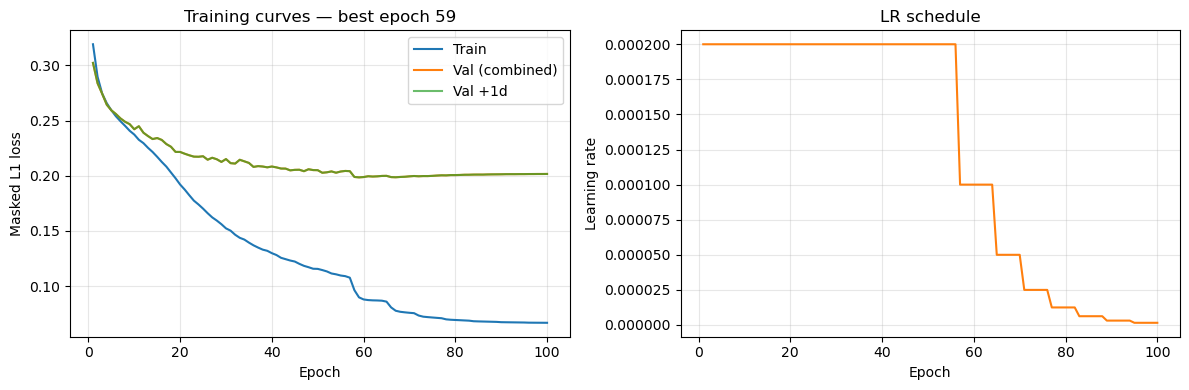

Best val loss: 0.198520 at epoch 59
Saved plot: PNG/training_loss_curve.png


In [6]:
import matplotlib.pyplot as plt

CHECKPOINT_DIR = "Models/fix_window"
RUN_NAME = "fix_window_16_19_dt96"
# RUN_NAME = "fix_window_10_19_dt96"  # 2010–2019, DT=96
# RUN_NAME = "fix_window_10_19"  # DT = 24
# RUN_NAME = "fix_window"  # legacy 16_19 daily run
history_path = f"{CHECKPOINT_DIR}/history/training_history_{RUN_NAME}.pt"

hist = torch.load(history_path, map_location="cpu")
epochs = hist["epoch"]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(epochs, hist["train"], label="Train")
ax[0].plot(epochs, hist["val"], label="Val (combined)")
ax[0].plot(epochs, hist["val1"], label="Val +1d", alpha=0.7)
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Masked L1 loss")
ax[0].set_title(f"Training curves — best epoch {hist['best_epoch']}")
ax[0].legend()
ax[0].grid(True, alpha=0.3)

ax[1].plot(epochs, hist["lr"], color="tab:orange")
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Learning rate")
ax[1].set_title("LR schedule")
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
os.makedirs("PNG", exist_ok=True)
plt.savefig("PNG/training_loss_curve.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Best val loss: {hist['best_val_loss']:.6f} at epoch {hist['best_epoch']}")
print(f"Saved plot: PNG/training_loss_curve.png")

In [5]:
data.std()

tensor(0.2463)

In [6]:
data.max()-data.min()

tensor(3.6727)

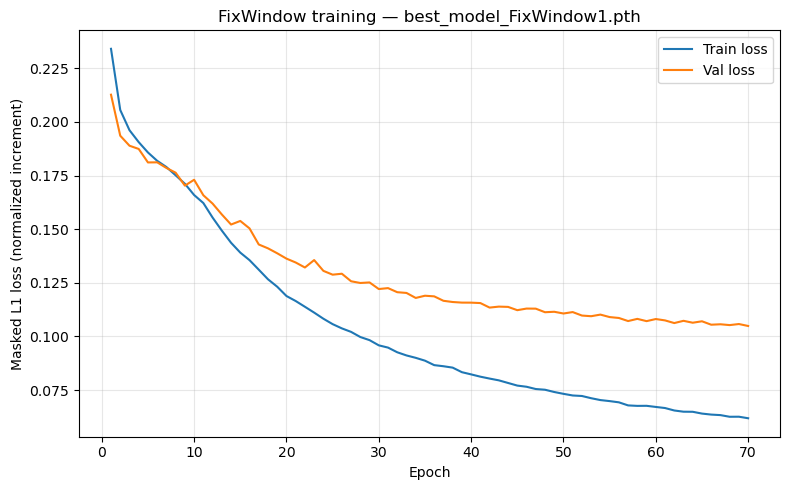

In [1]:
import json, re
import matplotlib.pyplot as plt

with open("02_train_unet2d_fix_window.ipynb") as f:
    nb = json.load(f)

text = ""
for cell in nb["cells"]:
    for out in cell.get("outputs", []):
        if out.get("output_type") == "stream":
            text += "".join(out.get("text", []))

epochs, train_loss, val_loss = [], [], []
for line in text.splitlines():
    m = re.match(
        r"Epoch (\d+) \| Train Loss: ([0-9.]+) \| Val Loss:([0-9.]+)", line
    )
    if m:
        epochs.append(int(m.group(1)))
        train_loss.append(float(m.group(2)))
        val_loss.append(float(m.group(3)))

plt.figure(figsize=(8, 5))
plt.plot(epochs, train_loss, label="Train loss")
plt.plot(epochs, val_loss, label="Val loss")
plt.xlabel("Epoch")
plt.ylabel("Masked L1 loss (normalized increment)")
plt.title("Fix-window training — Models/best_model_FixWindow1.pth")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("PNG/training_loss_curve.png", dpi=150)
plt.show()